In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries are working!")

All libraries are working!


In [ ]:

import pandas as pd
import numpy as np
# Same output every time, so results stay reproducible
np.random.seed(42)
# Generate 60 months of dates
dates = pd.date_range(
    start="2021-01-01",
    periods=60,
    freq="MS"
)
# Gradually increasing sales trend
trend = np.arange(60) * 300
# Seasonal pattern: sales rise and fall during the year
seasonality = 2000 * np.sin(2 * np.pi * np.arange(60) / 12)
# Random variation in sales
noise = np.random.normal(0, 700, 60)
# Combine the three components
sales = 10000 + trend + seasonality + noise
# Create a DataFrame
df = pd.DataFrame({
    "Month": dates,
    "Sales": sales.round(2)
})
# Save the dataset as a CSV file
df.to_csv("sales.csv", index=False)
# Display the generated data
display(df.head(10))
print("Total rows:", len(df))
print("Dataset saved successfully as sales.csv")

,Month,Sales
0,2021-01-01,10347.70
1,2021-02-01,11203.21
2,2021-03-01,12785.43
3,2021-04-01,13966.12
4,2021-05-01,12768.14
5,2021-06-01,12336.10
6,2021-07-01,12905.45
7,2021-08-01,11637.20
8,2021-09-01,10339.32
9,2021-10-01,11079.79


Total rows: 60
Dataset saved successfully as sales.csv


In [5]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nStatistical summary:")
display(df.describe())

Dataset shape: (60, 2)

Column names:
['Month', 'Sales']

Data types:
Month    datetime64[us]
Sales           float64
dtype: object

Missing values:
Month    0
Sales    0
dtype: int64

Statistical summary:


,Month,Sales
count,60,60.000000
mean,2023-06-16 20:48:00,18741.741333
min,2021-01-01 00:00:00,10339.320000
25%,2022-03-24 06:00:00,14098.000000
50%,2023-06-16 00:00:00,18685.885000
75%,2024-09-08 12:00:00,23524.420000
max,2025-12-01 00:00:00,27382.880000
std,NaN,5230.269848


In [6]:

# Dataset ki first 5 rows
display(df.head())

# Rows aur columns ki total count
print("Dataset shape:", df.shape)

# Column names aur data types
print("\nDataset information:")
df.info()

# Missing values check karo
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows check karo
print("\nDuplicate rows:", df.duplicated().sum())

,Month,Sales
0,2021-01-01,10347.70
1,2021-02-01,11203.21
2,2021-03-01,12785.43
3,2021-04-01,13966.12
4,2021-05-01,12768.14


Dataset shape: (60, 2)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Month   60 non-null     datetime64[us]
 1   Sales   60 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.1 KB

Missing values:
Month    0
Sales    0
dtype: int64

Duplicate rows: 0


In [7]:

# Month ko proper datetime format mein convert karo
df["Month"] = pd.to_datetime(df["Month"], errors="coerce")

# Sales ko numeric format mein convert karo
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# Invalid ya missing values wali rows hatao
df = df.dropna(subset=["Month", "Sales"])

# Month ke according data sort karo
df = df.sort_values("Month").reset_index(drop=True)

# Final check
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nFinal dataset shape:", df.shape)

display(df.head())

Missing values after cleaning:
Month    0
Sales    0
dtype: int64

Final dataset shape: (60, 2)


,Month,Sales
0,2021-01-01,10347.70
1,2021-02-01,11203.21
2,2021-03-01,12785.43
3,2021-04-01,13966.12
4,2021-05-01,12768.14


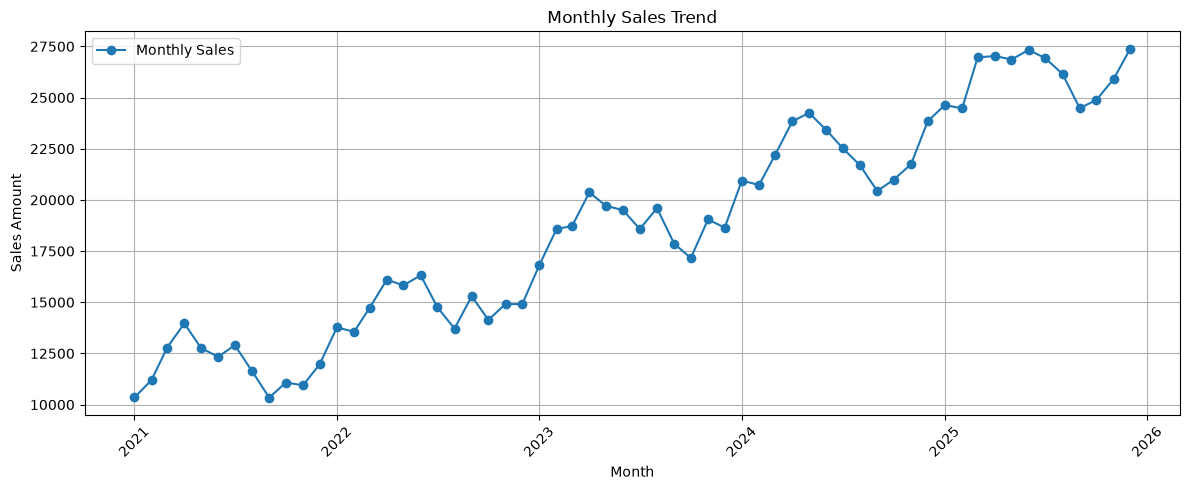

In [8]:

plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"],
    df["Sales"],
    marker="o",
    label="Monthly Sales"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

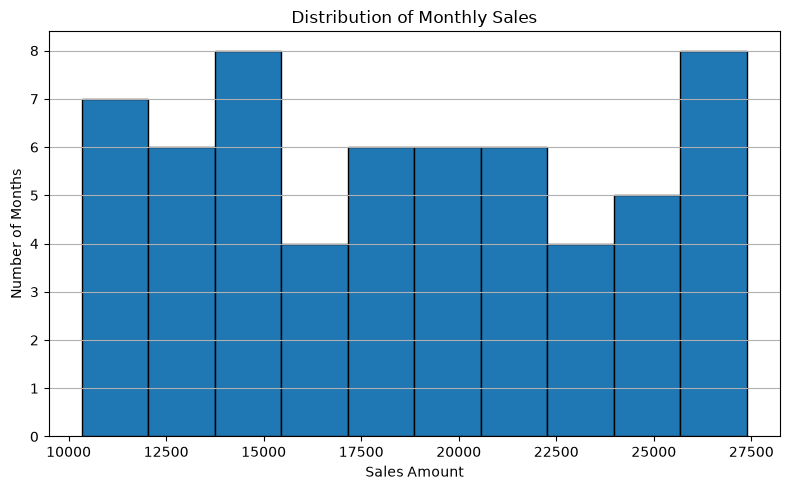

In [9]:

plt.figure(figsize=(8, 5))

plt.hist(df["Sales"], bins=10, edgecolor="black")

plt.title("Distribution of Monthly Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Months")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [10]:

print("Average monthly sales:", round(df["Sales"].mean(), 2))
print("Highest monthly sales:", round(df["Sales"].max(), 2))
print("Lowest monthly sales:", round(df["Sales"].min(), 2))
print("Total sales:", round(df["Sales"].sum(), 2))

Average monthly sales: 18741.74
Highest monthly sales: 27382.88
Lowest monthly sales: 10339.32
Total sales: 1124504.48


In [11]:

# Create a copy of the dataset
df_model = df.copy()

# Extract date-related features
df_model["Year"] = df_model["Month"].dt.year
df_model["Month_Number"] = df_model["Month"].dt.month

# Previous month's sales
df_model["Lag_1"] = df_model["Sales"].shift(1)

# Average sales of the previous 3 months
df_model["Rolling_Mean_3"] = (
    df_model["Sales"].shift(1).rolling(window=3).mean()
)

# Display the new features
display(df_model.head(10))

,Month,Sales,Year,Month_Number,Lag_1,Rolling_Mean_3
0,2021-01-01,10347.70,2021,1,NaN,NaN
1,2021-02-01,11203.21,2021,2,10347.70,NaN
2,2021-03-01,12785.43,2021,3,11203.21,NaN
3,2021-04-01,13966.12,2021,4,12785.43,11445.446667
4,2021-05-01,12768.14,2021,5,13966.12,12651.586667
5,2021-06-01,12336.10,2021,6,12768.14,13173.230000
6,2021-07-01,12905.45,2021,7,12336.10,13023.453333
7,2021-08-01,11637.20,2021,8,12905.45,12669.896667
8,2021-09-01,10339.32,2021,9,11637.20,12292.916667
9,2021-10-01,11079.79,2021,10,10339.32,11627.323333


In [12]:

print("Missing values before cleaning:")
print(df_model.isnull().sum())

# Remove rows that don't have enough previous-month data
df_model = df_model.dropna().reset_index(drop=True)

print("\nMissing values after cleaning:")
print(df_model.isnull().sum())

print("\nFinal shape:", df_model.shape)

display(df_model.head())

Missing values before cleaning:
Month             0
Sales             0
Year              0
Month_Number      0
Lag_1             1
Rolling_Mean_3    3
dtype: int64

Missing values after cleaning:
Month             0
Sales             0
Year              0
Month_Number      0
Lag_1             0
Rolling_Mean_3    0
dtype: int64

Final shape: (57, 6)


,Month,Sales,Year,Month_Number,Lag_1,Rolling_Mean_3
0,2021-04-01,13966.12,2021,4,12785.43,11445.446667
1,2021-05-01,12768.14,2021,5,13966.12,12651.586667
2,2021-06-01,12336.10,2021,6,12768.14,13173.230000
3,2021-07-01,12905.45,2021,7,12336.10,13023.453333
4,2021-08-01,11637.20,2021,8,12905.45,12669.896667


In [13]:

features = [
    "Year",
    "Month_Number",
    "Lag_1",
    "Rolling_Mean_3"
]

X = df_model[features]
y = df_model["Sales"]

print("Input features (X):")
display(X.head())

print("Target values (y):")
display(y.head())

Input features (X):


,Year,Month_Number,Lag_1,Rolling_Mean_3
0,2021,4,12785.43,11445.446667
1,2021,5,13966.12,12651.586667
2,2021,6,12768.14,13173.230000
3,2021,7,12336.10,13023.453333
4,2021,8,12905.45,12669.896667


Target values (y):


0    13966.12
1    12768.14
2    12336.10
3    12905.45
4    11637.20
Name: Sales, dtype: float64

In [14]:

# Keep the time order: older data first, newer data last
split_index = int(len(df_model) * 0.8)

train_data = df_model.iloc[:split_index]
test_data = df_model.iloc[split_index:]

features = ["Year", "Month_Number", "Lag_1", "Rolling_Mean_3"]

X_train = train_data[features]
y_train = train_data["Sales"]

X_test = test_data[features]
y_test = test_data["Sales"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining period:")
print(train_data["Month"].min(), "to", train_data["Month"].max())

print("\nTesting period:")
print(test_data["Month"].min(), "to", test_data["Month"].max())

Training rows: 45
Testing rows: 12

Training period:
2021-04-01 00:00:00 to 2024-12-01 00:00:00

Testing period:
2025-01-01 00:00:00 to 2025-12-01 00:00:00


In [15]:

from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict sales for the test period
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")
print("\nFirst 5 predictions:")
print(lr_predictions[:5])

Linear Regression model trained successfully!

First 5 predictions:
[25447.27983285 25705.8139315  25368.98353489 26817.44415997
 26672.38801556]


In [16]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("\nFirst 5 predictions:")
print(rf_predictions[:5])

Random Forest model trained successfully!

First 5 predictions:
[23844.67535 23183.0248  23148.2794  23184.988   23195.2675 ]


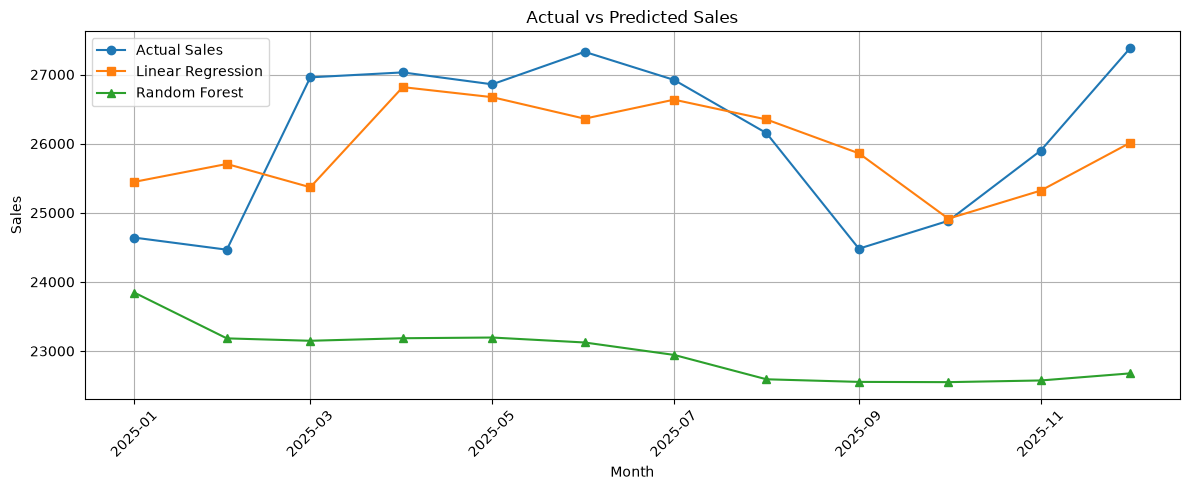

In [17]:

plt.figure(figsize=(12, 5))

plt.plot(
    test_data["Month"],
    y_test.values,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    test_data["Month"],
    lr_predictions,
    marker="s",
    label="Linear Regression"
)

plt.plot(
    test_data["Month"],
    rf_predictions,
    marker="^",
    label="Random Forest"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Calculate evaluation metrics for Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_predictions)
)

lr_mape = np.mean(
    np.abs((y_test.values - lr_predictions) / y_test.values)
) * 100

# Calculate evaluation metrics for Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_mape = np.mean(
    np.abs((y_test.values - rf_predictions) / y_test.values)
) * 100

print("Linear Regression")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("MAPE:", round(lr_mape, 2), "%")

print("\nRandom Forest")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("MAPE:", round(rf_mape, 2), "%")

Linear Regression
MAE: 737.1
RMSE: 911.39
MAPE: 2.84 %

Random Forest
MAE: 3119.45
RMSE: 3336.07
MAPE: 11.79 %


In [19]:

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "MAPE (%)": [lr_mape, rf_mape]
})

results = results.round(2)

display(results)

,Model,MAE,RMSE,MAPE (%)
0,Linear Regression,737.10,911.39,2.84
1,Random Forest,3119.45,3336.07,11.79


In [20]:

if lr_mae <= rf_mae:
    best_model = lr_model
    best_name = "Linear Regression"
    best_predictions = lr_predictions
else:
    best_model = rf_model
    best_name = "Random Forest"
    best_predictions = rf_predictions

print("Best model based on test MAE:", best_name)
print("Test MAE:", round(min(lr_mae, rf_mae), 2))

Best model based on test MAE: Linear Regression
Test MAE: 737.1


In [21]:

# Start with the latest available sales history
history = df[["Month", "Sales"]].copy()

future_forecasts = []

for i in range(6):

    # Next month ki date
    next_month = history["Month"].max() + pd.offsets.MonthBegin(1)

    # Past sales se features create karo
    last_sales = history["Sales"].iloc[-1]
    rolling_mean = history["Sales"].tail(3).mean()

    input_data = pd.DataFrame({
        "Year": [next_month.year],
        "Month_Number": [next_month.month],
        "Lag_1": [last_sales],
        "Rolling_Mean_3": [rolling_mean]
    })

    # Selected model se sales predict karo
    predicted_sales = best_model.predict(input_data[features])[0]

    # Forecast ko save karo
    future_forecasts.append({
        "Month": next_month,
        "Predicted_Sales": round(max(0, predicted_sales), 2)
    })

    # Prediction ko history mein add karo
    history = pd.concat([
        history,
        pd.DataFrame({
            "Month": [next_month],
            "Sales": [max(0, predicted_sales)]
        })
    ], ignore_index=True)

# Forecast table
forecast_df = pd.DataFrame(future_forecasts)

display(forecast_df)

,Month,Predicted_Sales
0,2026-01-01,28934.13
1,2026-02-01,29673.43
2,2026-03-01,29880.80
3,2026-04-01,29820.20
4,2026-05-01,29695.90
5,2026-06-01,29591.81


In [22]:

forecast_df.to_csv("sales_forecast.csv", index=False)

print("Forecast saved successfully!")
print("File name: sales_forecast.csv")

Forecast saved successfully!
File name: sales_forecast.csv


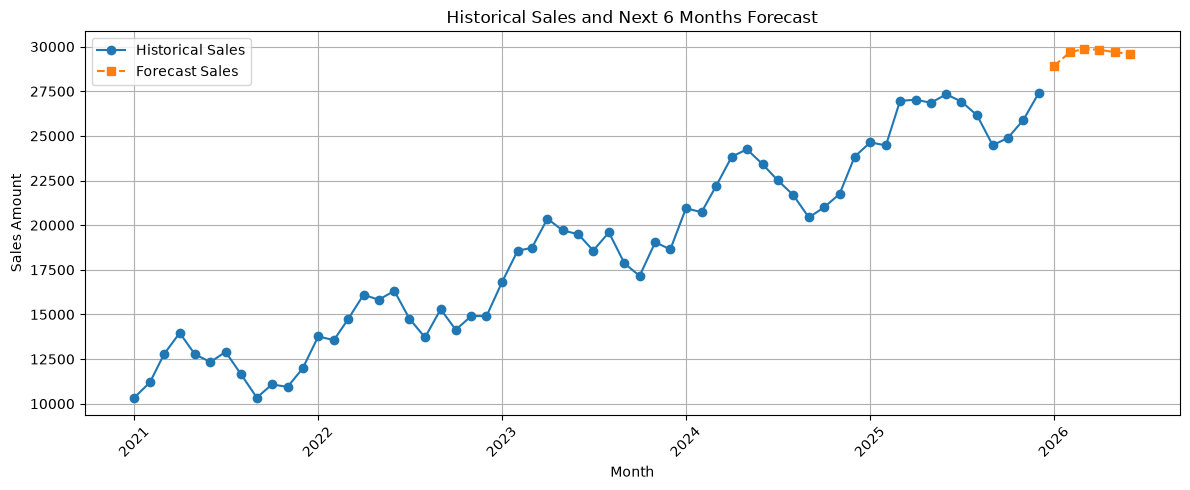

In [23]:

plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"],
    df["Sales"],
    label="Historical Sales",
    marker="o"
)

plt.plot(
    forecast_df["Month"],
    forecast_df["Predicted_Sales"],
    label="Forecast Sales",
    marker="s",
    linestyle="--"
)

plt.title("Historical Sales and Next 6 Months Forecast")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()